# Plots for Paper

## Imports and loading data

In [1]:
from pathlib import Path

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import scienceplots
import xarray as xr

from data import get_binned_err, get_data, get_raw_data
from utils import pretty_model_names

assert scienceplots
plt.style.use(["science", "notebook"])

In [2]:
data = get_data()
X = data[["colon10", "agex", "age", "sex", "pyr", "stratum_id"]]
y = data.solid.values

In [3]:
raw_data = get_raw_data()
raw_data

,city,sex,gd3,ahs,agexcat,agecat,ctime,dosecat,subjects,pyr,...,leukemia,lymphoma,myeloma,blooddis,cvd,respiratory,digestive,genitourinary,inf,external
0,1,1,1,0,1,2,1,1,259.0,594.82683,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,1,1,0,1,2,1,2,726.0,1701.26762,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,1,1,0,1,2,1,3,277.0,571.16359,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,1,1,1,0,1,2,1,4,151.0,335.21561,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,1,1,1,0,1,2,1,5,109.0,252.33539,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53777,2,2,2,2,11,17,6,1,0.0,9.50103,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
53778,2,2,2,2,11,18,5,1,0.0,0.27858,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
53779,2,2,2,2,11,18,6,1,0.0,9.34086,...,0.0,0.0,0.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0
53780,2,2,2,2,11,18,7,1,0.0,3.33333,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
print("total num ppl", raw_data.subjects.sum())

total num ppl 86611.0


In [5]:
print(
    "average dose, weighted by number of people (mGy)",
    np.average(raw_data.colon10, weights=raw_data.subjects),
)

average dose, weighted by number of people (mGy) 117.42891851600837


In [6]:
print(
    "percentage of people who received a dose less than 50 mGy",
    np.sum(raw_data.subjects[raw_data.colon10 < 50]) / raw_data.subjects.sum(),
)

percentage of people who received a dose less than 50 mGy 0.7252658438304603


## Load figure data


In [7]:
figures_folder = Path("../results/figures")
model_names = [
    "linear",
    "linear_quadratic",
    "quadratic",
    "linear_bart",
    "linear_quadratic_bart",
    "quadratic_bart",
    "varying_coefficient_bart",
]

figs = {}
for model_name in model_names:
    path = figures_folder / f"{model_name}_figures.nc"
    if path.exists():
        figs[model_name] = xr.load_dataset(path)
    else:
        print(f"Missing {path.name}")
print(f"Loaded figure data for: {list(figs)}")

Loaded figure data for: ['linear', 'linear_quadratic', 'quadratic', 'linear_bart', 'linear_quadratic_bart', 'quadratic_bart', 'varying_coefficient_bart']


## Diagnostics and Posteriors

In [ ]:
# Read idata files from results/idata directory
idata_folder = Path("../results/idata")
idata_dict = {}

for model_name in model_names:
    nc_file = idata_folder / f"{model_name}_idata.nc"
    if not nc_file.exists():
        print(f"Missing {nc_file.name}")
        continue
    idata_dict[model_name] = az.from_netcdf(nc_file)
    print(f"\n{'-' * 80}\nLoaded {model_name}: {nc_file.name}")

    var_names = []
    for dv in idata_dict[model_name].posterior.data_vars:
        if (
            len(idata_dict[model_name].posterior[dv].dims) == 2
            or "beta_dim_0" in idata_dict[model_name].posterior[dv].dims
        ):
            var_names.append(dv)
    if var_names:
        summary = az.summary(idata_dict[model_name], var_names=var_names)
        print(summary)
        stats = idata_dict[model_name].sample_stats
        if "diverging" in stats:
            print(f"Divergences: {stats.diverging.sum().item()}")
    if "bart_probe" in idata_dict[model_name].posterior:
        bart_probe = idata_dict[model_name].posterior["bart_probe"]
        differences = (bart_probe - bart_probe.isel(probe_row=0)).isel(
            probe_row=slice(1, None)
        )
        differences = differences.to_dataset(name="bart_probe_difference")
        print(
            f"BART mixing (probe differences): max r_hat "
            f"{float(az.rhat(differences).to_array().max()):.3f}, "
            f"min bulk ESS {float(az.ess(differences).to_array().min()):.0f}"
        )
        raw = bart_probe.to_dataset()
        print(
            f"BART level drift (raw probes, not identified): max r_hat "
            f"{float(az.rhat(raw).to_array().max()):.3f}"
        )

# Display available models
if idata_dict:
    print(f"\nAvailable models: {list(idata_dict.keys())}")


--------------------------------------------------------------------------------
Loaded linear: linear_idata.nc
          mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
beta     0.416  0.052   0.315    0.511      0.001    0.001    6295.0   
beta_z0 -0.846  0.137  -1.103   -0.586      0.002    0.002    6065.0   
nu      -0.824  0.402  -1.575   -0.051      0.005    0.004    6561.0   
sigma    0.344  0.087   0.181    0.505      0.001    0.001    7708.0   
tau     -0.355  0.084  -0.510   -0.192      0.001    0.001    6164.0   

         ess_tail  r_hat  
beta       5477.0    1.0  
beta_z0    5664.0    1.0  
nu         5805.0    1.0  
sigma      6452.0    1.0  
tau        5222.0    1.0  
Divergences: 0

--------------------------------------------------------------------------------
Loaded linear_quadratic: linear_quadratic_idata.nc
          mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
beta[0]  0.356  0.082   0.205    0.513      0.001    0.001    6868.0   


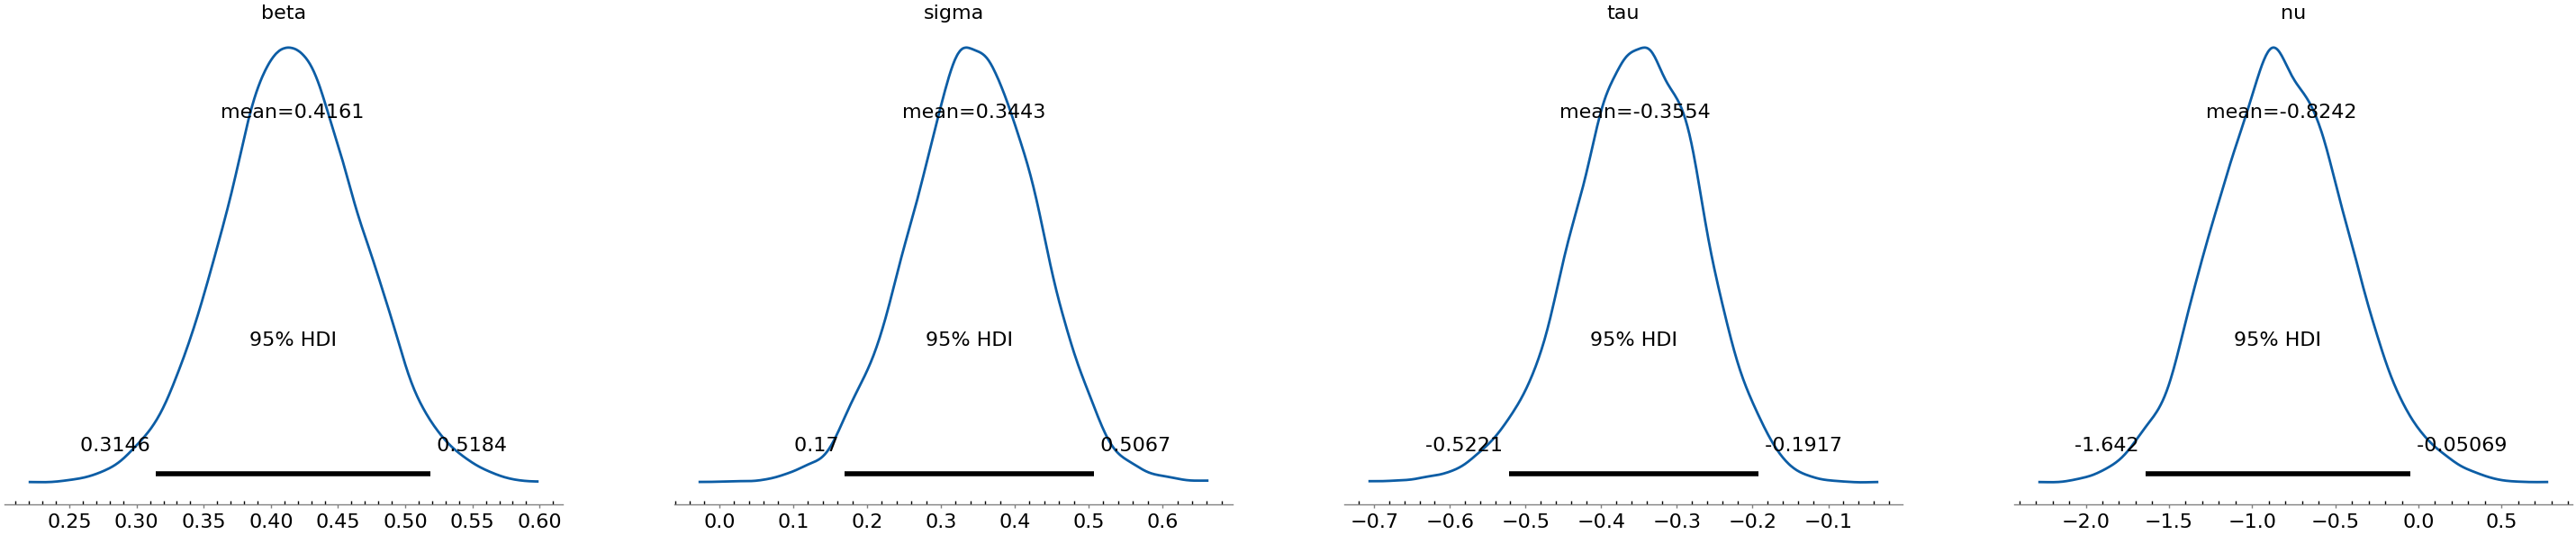

In [9]:
# Linear
az.plot_posterior(
    idata_dict["linear"].posterior,
    var_names=["beta", "sigma", "tau", "nu"],
    hdi_prob=0.95,
    round_to=4,
)
plt.show()

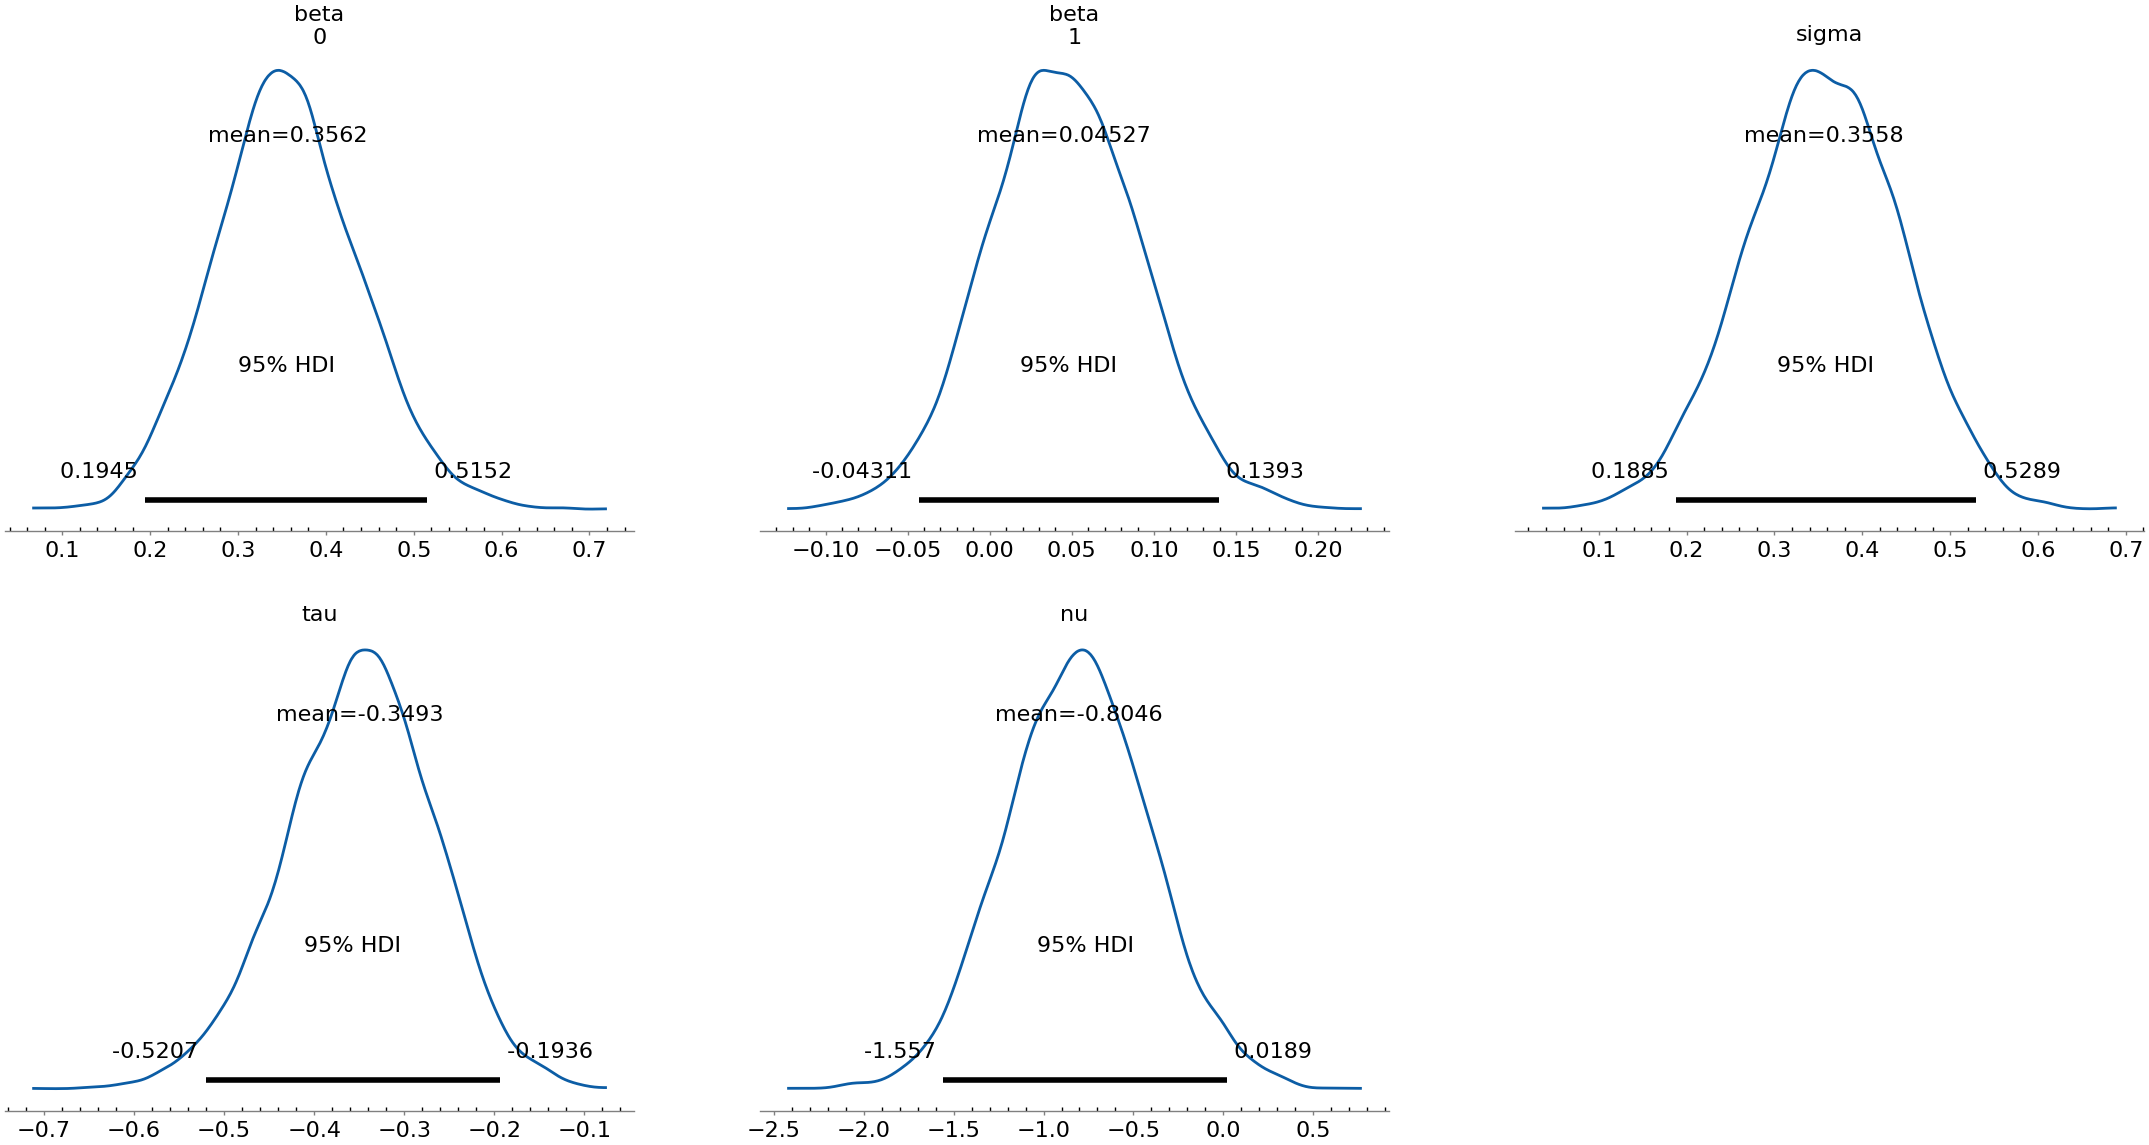

In [10]:
# Linear Quadratic
az.plot_posterior(
    idata_dict["linear_quadratic"].posterior,
    var_names=["beta", "sigma", "tau", "nu"],
    hdi_prob=0.95,
    round_to=4,
)
plt.show()

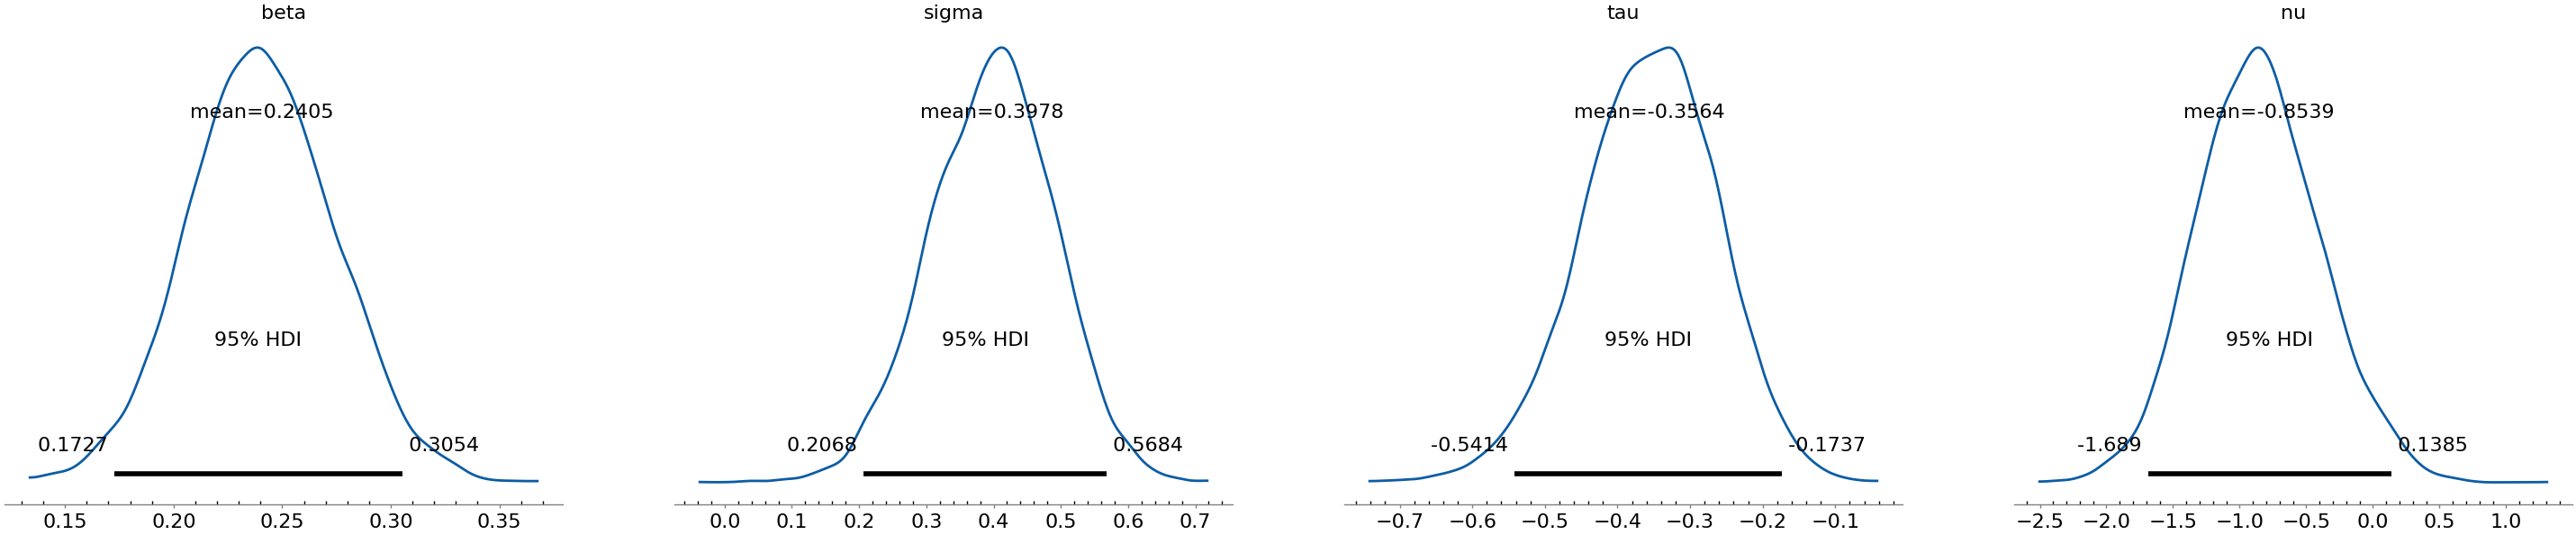

In [11]:
# Quadratic
az.plot_posterior(
    idata_dict["quadratic"].posterior,
    var_names=["beta", "sigma", "tau", "nu"],
    hdi_prob=0.95,
    round_to=4,
)
plt.show()

### Parametric BARTs

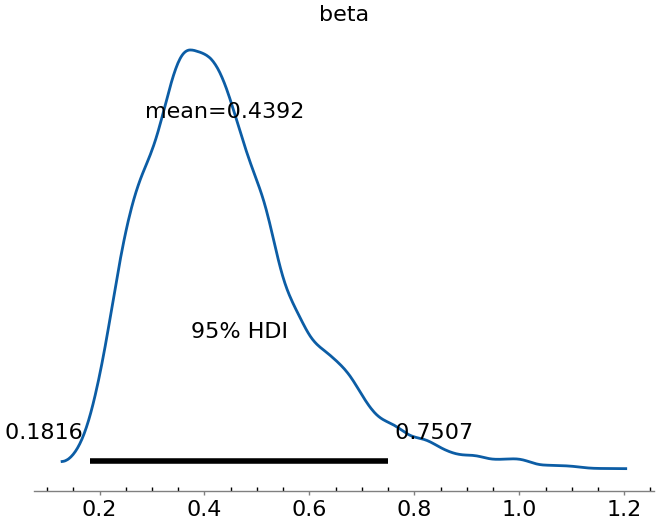

In [12]:
# Linear BART
az.plot_posterior(
    idata_dict["linear_bart"].posterior,
    var_names=["beta"],
    hdi_prob=0.95,
    round_to=4,
)
plt.show()

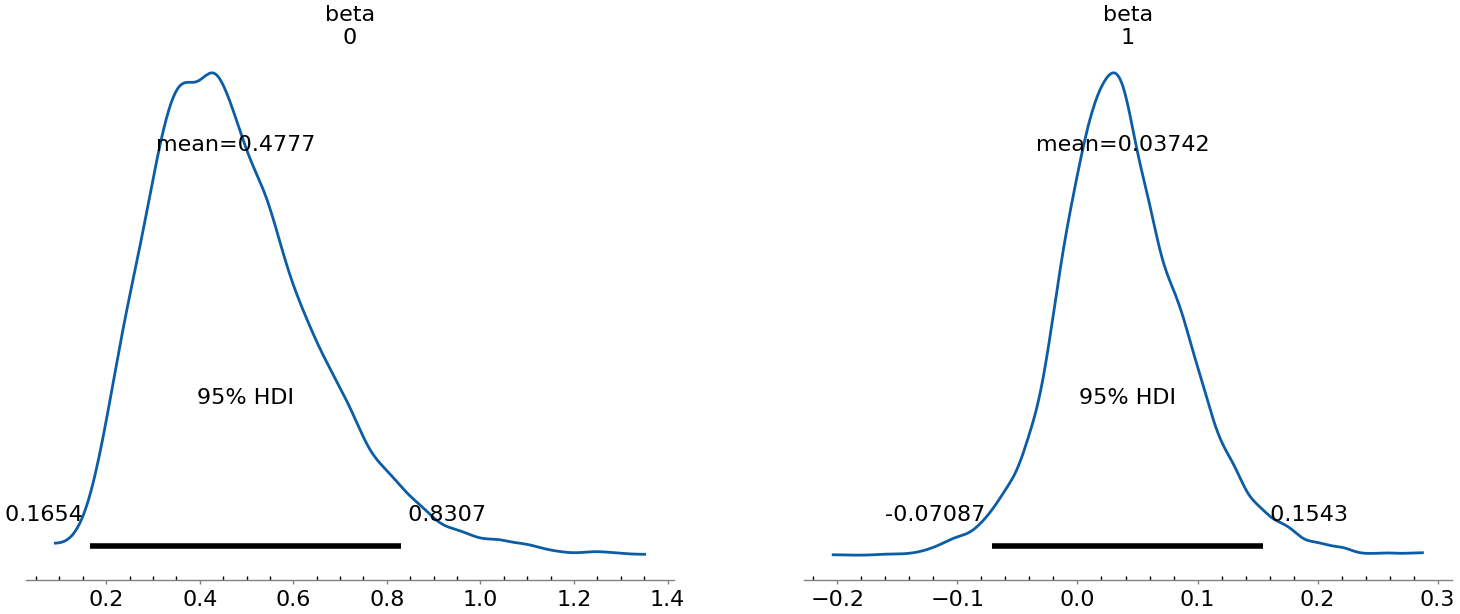

In [13]:
# Linear Quadratic BART
az.plot_posterior(
    idata_dict["linear_quadratic_bart"].posterior,
    var_names=["beta"],
    hdi_prob=0.95,
    round_to=4,
)
plt.show()

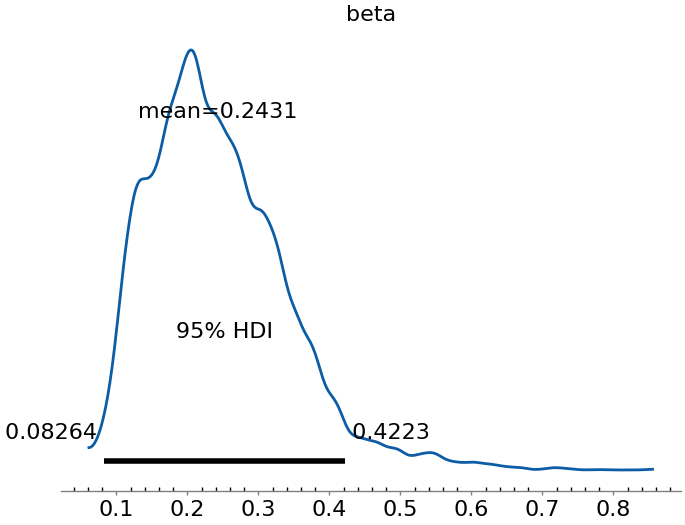

In [14]:
# Quadratic BART
az.plot_posterior(
    idata_dict["quadratic_bart"].posterior,
    var_names=["beta"],
    hdi_prob=0.95,
    round_to=4,
)
plt.show()

### Dose Response Curves

All dose-response curves are the excess relative risk at the reference profile: sex-averaged, exposed at age 30, attained age 70. Lines are posterior means and shaded regions are pointwise 95% highest density intervals (HDIs). The binned points are for the whole cohort, not the reference profile.

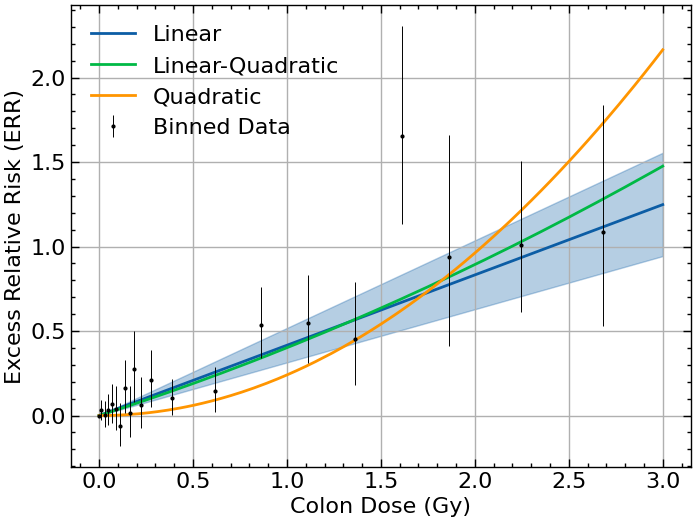

In [ ]:
REFERENCE_LABEL = "Excess Relative Risk (ERR)"


def plot_binned_data(color=None, max_dose=3):
    # ERR per dose category relative to 0-5 mGy, with 95% Wald CIs
    binned_err = get_binned_err(get_data())
    binned_err = binned_err[binned_err.colon10 < max_dose]

    plt.errorbar(
        binned_err.colon10,
        binned_err.err,
        yerr=[
            binned_err.err - binned_err.lower,
            binned_err.upper - binned_err.err,
        ],
        fmt="o",
        capsize=0,
        label="Binned Data",
        markersize=2,
        elinewidth=0.7,
        c=color,
    )


def plot_hdi_curve(x, draws, hdi_prob=0.95, include_ci=True, **kwargs):
    """Posterior mean and pointwise HDI of a curve"""
    draws = np.asarray(draws).reshape(-1, len(x))
    line = plt.plot(x, draws.mean(axis=0), **kwargs)[0]
    if include_ci:
        hdi = az.hdi(draws[None], hdi_prob=hdi_prob)
        plt.fill_between(x, hdi[:, 0], hdi[:, 1], color=line.get_color(), alpha=0.3)


def plot_dose_response(model_name, include_ci=True, include_labels=True):
    # ERR at the reference profile (see figure_data.err_reference)
    err = figs[model_name].err_reference
    plot_hdi_curve(
        err.dose.values,
        err.values,
        include_ci=include_ci,
        label=pretty_model_names[model_name],
    )

    if include_labels:
        plt.xlabel("Colon Dose (Gy)")
        plt.ylabel(REFERENCE_LABEL)


plot_dose_response("linear")
plot_dose_response("linear_quadratic", include_ci=False, include_labels=False)
plot_dose_response("quadratic", include_ci=False, include_labels=False)
plot_binned_data(color="black")
plt.grid()
plt.legend()
plt.show()

## Partial Dependence of the Log Effect Modification

In [16]:
from scipy.stats import pearsonr

pearsonr(X.age, X.agex)

PearsonRResult(statistic=np.float64(0.6900757891132916), pvalue=np.float64(0.0))

In [17]:
data.age.min(), data.age.max()

(np.float64(7.60096), np.float64(113.29021))

In [18]:
data.agex.min(), data.agex.max()

(np.float64(0.05749), np.float64(88.6258))

In [19]:
def pretty_ice_labels(axes):
    axes[0].set_xlabel("Age at Exposure")
    axes[0].set_xticks([10, 45, 80])

    axes[1].set_xlabel("Attained Age")
    axes[1].set_xticks([10, 50, 90])

    axes[2].set_xlabel("Sex")
    axes[2].set_xticks([-1, 1])
    axes[2].set_xticklabels(["Male", "Female"])

In [20]:
def plot_log_effect_mod_pd(model_name, title, hdi_prob=0.95):
    """Partial dependence of the log effect modifier on agex, age and sex"""
    data = figs[model_name]
    fig, axes = plt.subplots(1, 3, sharey=True, figsize=(12, 4))
    for ax, variable in zip(axes, ["agex", "age", "sex"]):
        grid = data[f"{variable}_grid"].values
        plt.sca(ax)
        ax.plot(
            grid, data[f"ice_{variable}"].values.T, color="C0", alpha=0.1, linewidth=0.5
        )
        plot_hdi_curve(
            grid, data[f"pd_{variable}"].values, hdi_prob=hdi_prob, color="C1"
        )
    axes[0].set_ylabel("Log Effect Modifier")
    pretty_ice_labels(axes)
    plt.tight_layout()
    plt.suptitle(title, y=1.02)

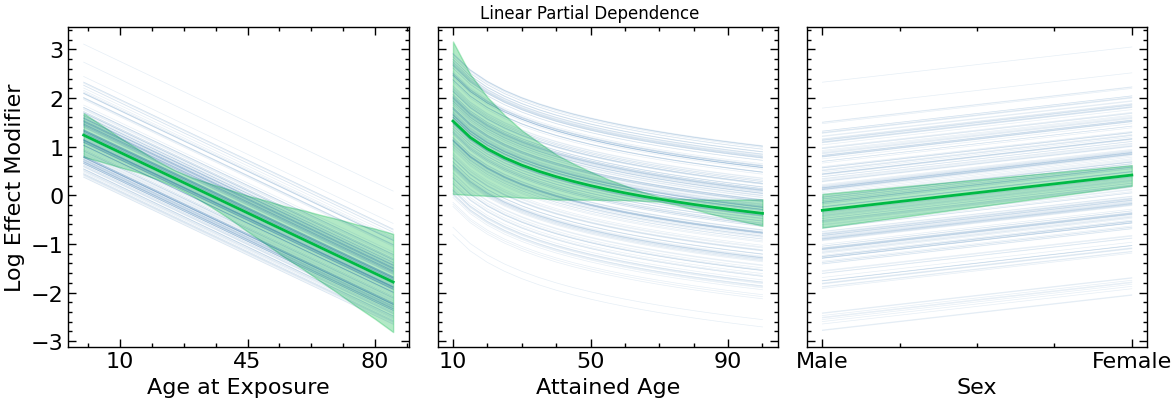

In [ ]:
plot_log_effect_mod_pd("linear", "Linear Partial Dependence")

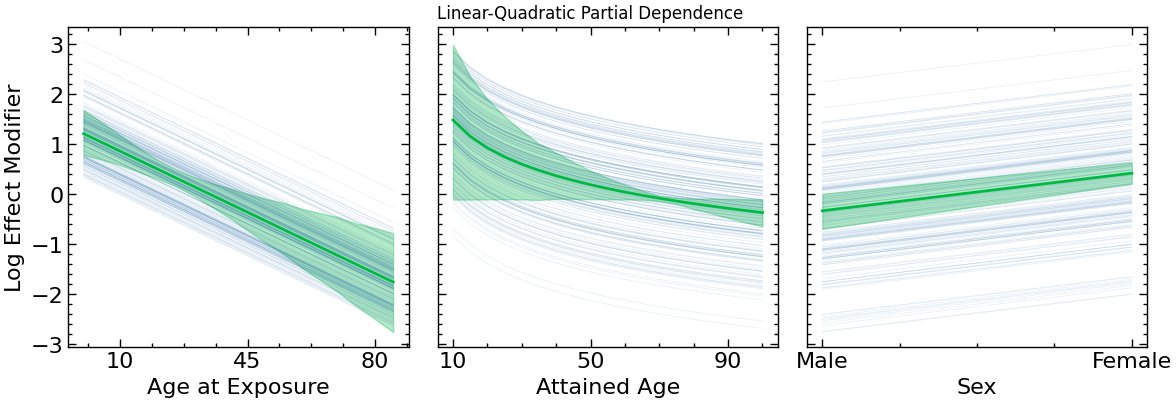

In [22]:
plot_log_effect_mod_pd("linear_quadratic", "Linear-Quadratic Partial Dependence")

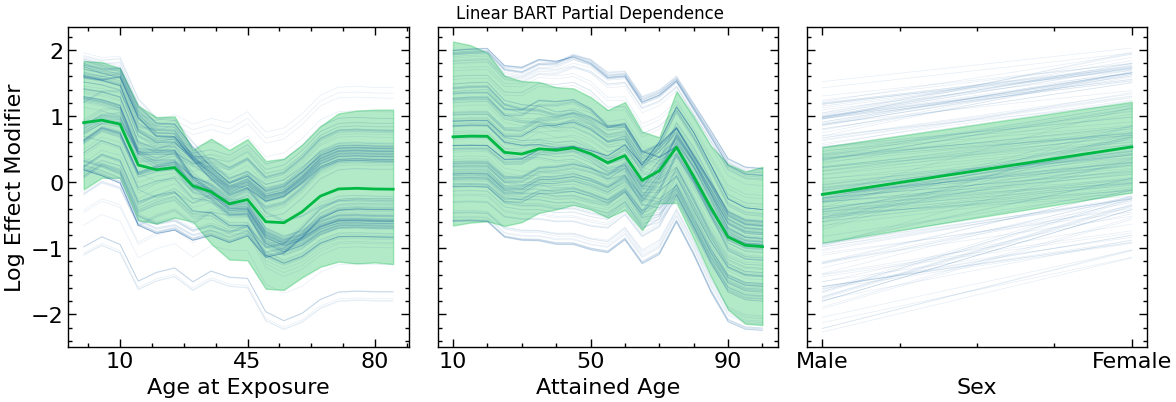

In [23]:
plot_log_effect_mod_pd("linear_bart", "Linear BART Partial Dependence")

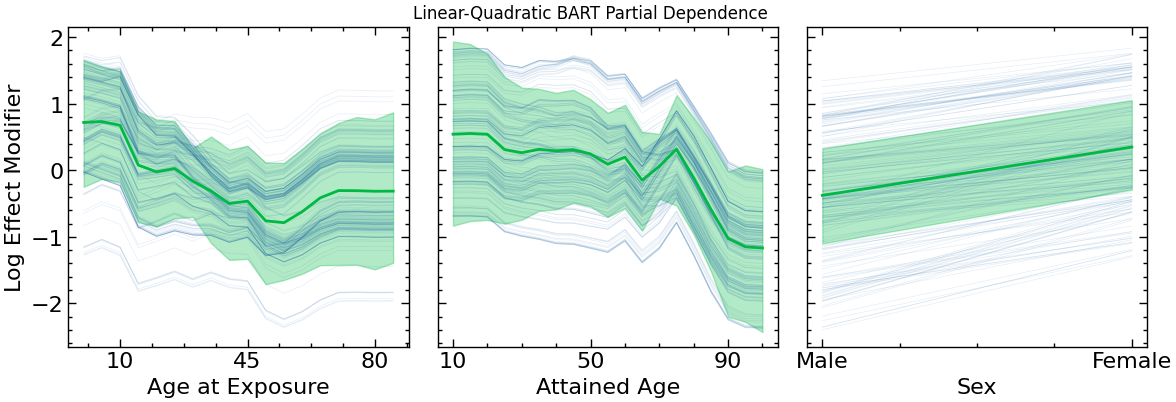

In [24]:
plot_log_effect_mod_pd(
    "linear_quadratic_bart", "Linear-Quadratic BART Partial Dependence"
)

In [25]:
# Each sampled row's log RR at 1 Gy (relative to 0 Gy) against its covariates


def plot_bart_effect_mod(model_name):
    data = figs[model_name]
    fig, axes = plt.subplots(1, 3, sharey=True, figsize=(12, 4))
    for ax, column in zip(axes, ["agex", "age", "sex"]):
        ax.scatter(data[f"row_{column}"], data.log_rr_at_dose, s=5, alpha=0.5)
    axes[0].set_ylabel("Log Relative Risk at 1 Gy")
    pretty_ice_labels(axes)
    plt.tight_layout()
    plt.suptitle(f"{pretty_model_names[model_name]} Effect Modification", y=1.02)

In [26]:
def bart_pdp(ax, c="C0", model_name="varying_coefficient_bart"):
    ax = plt.gca() if ax is None else ax
    plt.sca(ax)
    err = figs[model_name].err_reference
    plot_hdi_curve(
        err.dose.values, err.values, color=c, label=pretty_model_names[model_name]
    )
    ax.set_xlabel("Colon Dose (Gy)")
    ax.set_ylabel(REFERENCE_LABEL)

    return ax

### Varying-coefficient BART

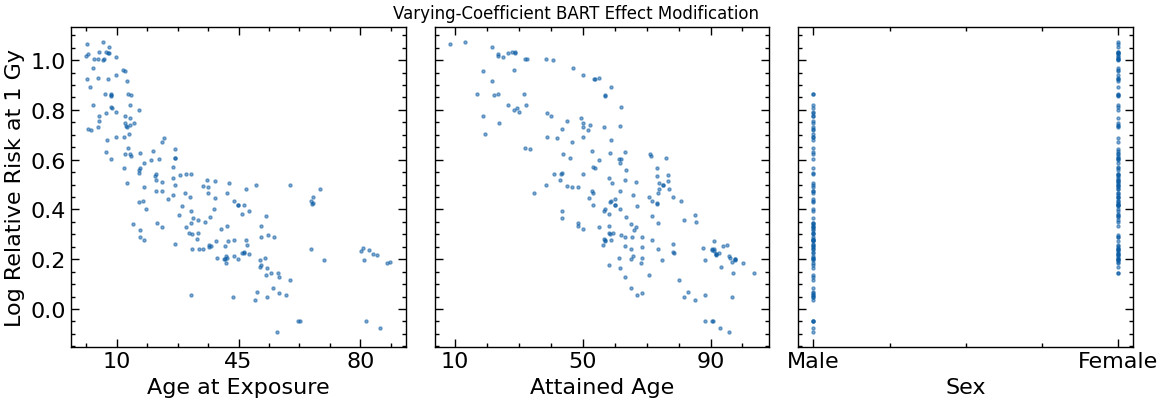

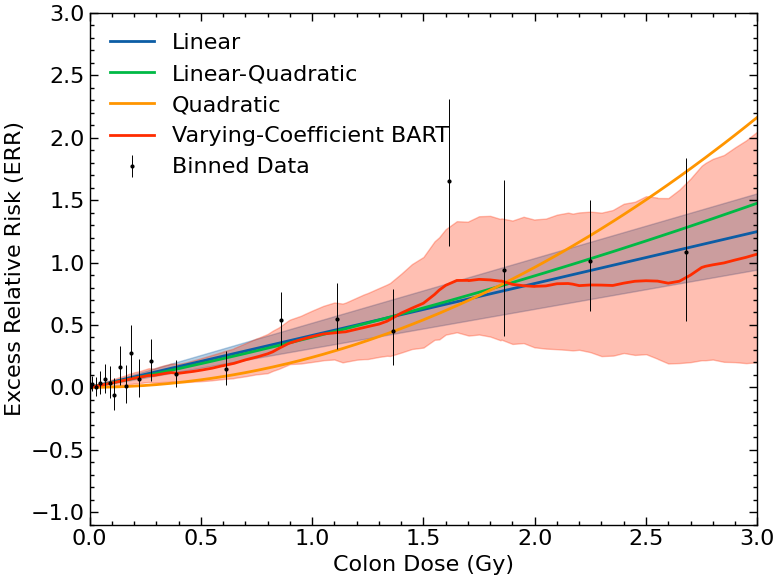

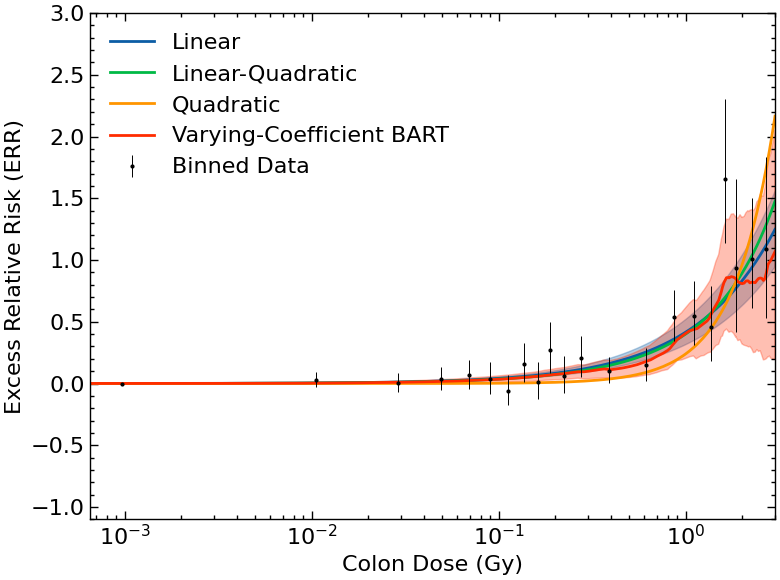

In [27]:
if "varying_coefficient_bart" in figs:
    plot_bart_effect_mod("varying_coefficient_bart")
    for log_x in [False, True]:
        fig, ax = plt.subplots()
        plot_dose_response("linear", include_ci=True, include_labels=False)
        plot_dose_response("linear_quadratic", include_ci=False, include_labels=False)
        plot_dose_response("quadratic", include_ci=False, include_labels=False)
        bart_pdp(ax, c="C3", model_name="varying_coefficient_bart")
        plot_binned_data(color="black")
        if log_x:
            plt.semilogx()
            plt.xlim(right=3)
        else:
            plt.xlim(0, 3)
        plt.ylim(-1.1, 3)
        plt.tight_layout()
        plt.legend()
        plt.show()